# 02 · Manifold — cell-state trajectory

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

### Setup & paths

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load manifold · re-score modules · graph-smooth

In [3]:
# load processed manifold; re-score developmental modules (canonical), graph-smooth for geography
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 7830 cells
Gast: 73/81 genes present
pSom: 85/98 genes present
Crest: 103/104 genes present
raw module means (honest readout): {'Gast': -0.0112, 'pSom': 0.0718, 'Crest': -0.0236}


### Topology decision — branching vs non-branching

In [4]:
# TOPOLOGY from the embedding + biology, not a metric alone.
# (a) UMAP shape; (b) does a Gast/pSom hub DIVERGE into two arms (branching), or do the programs
#     co-express / overlap into a single axis (non-branching)?
xy = adata.obsm['X_umap']; c = xy - xy.mean(0); _,s,_ = np.linalg.svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor): {s[0]/s[1]:.2f}  (~1 = single blob, no two arms)')
# hub / cross-repression test on the developmental programs
gz=(adata.obs['Gast']-adata.obs['Gast'].mean())/adata.obs['Gast'].std()
pz=(adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz=(adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
jgp=((gz>0.5)&(pz>0.5)).mean()/((gz>0.5).mean()*(pz>0.5).mean())
print(f'Gast&pSom joint-high enrichment = {jgp:.2f}  (>1 = co-express, NOT competing arms)')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  smoothed geography {a} vs {b}: r = {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
# PPT tree probe: fits many spurious forks on a blob (over-fit) -> tree not supported by embedding
ppt = adata.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ppt, method='ppt', Nodes=150, ppt_lambda=3000, ppt_sigma=1.0,
                use_rep='X_umap', seed=SEED, plot=False)
Bp = np.asarray(ppt.uns['graph']['B']); degp=(Bp>0).sum(0)
print(f'PPT tree probe: {int((degp==1).sum())} tips / {int((degp>=3).sum())} forks '
      f'-- forks are blob over-fit, not two dev-signature arms')
print('DECISION: Gast/pSom co-express (no mutual-exclusion hub), single blob -> NON-BRANCHING -> fit a curve')

UMAP principal-axis ratio (major/minor): 1.10  (~1 = single blob, no two arms)
Gast&pSom joint-high enrichment = 1.13  (>1 = co-express, NOT competing arms)
  smoothed geography Gast_sm vs pSom_sm: r = +0.26
  smoothed geography Crest_sm vs Gast_sm: r = -0.75
  smoothed geography Crest_sm vs pSom_sm: r = -0.65
PPT tree probe: 4 tips / 2 forks -- forks are blob over-fit, not two dev-signature arms
DECISION: Gast/pSom co-express (no mutual-exclusion hub), single blob -> NON-BRANCHING -> fit a curve


### Fit principal curve · fold check · proliferation orthogonality

In [5]:
# fit scFates principal curve; fold check on an INDEPENDENT metric (graph distance vs euclidean),
# NOT neighbours read off the embedding being tested; no re-embedding of the manifold
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    return dmin/med, int(((B>0).sum(0)==1).sum()), int(((B>0).sum(0)>=3).sum())
sub = adata
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'
print('proliferation orthogonality (keep whole manifold, no scoping):')
g2m=pd.to_numeric(sub.obs['g2m_score'],errors='coerce').fillna(0).values
g1s=pd.to_numeric(sub.obs['g1s_score'],errors='coerce').fillna(0).values
cyc=np.maximum(g1s,g2m)
for m in ['Gast','pSom','Crest']:
    rho,_=spearmanr(cyc,sub.obs[m].values); print(f'  {m} vs cycling: rho={rho:+.2f}')

curve: 2 tips, 0 forks | fold self-approach ratio = 2.52 (>1 = fold-free)
proliferation orthogonality (keep whole manifold, no scoping):
  Gast vs cycling: rho=-0.19
  pSom vs cycling: rho=-0.03
  Crest vs cycling: rho=+0.09


### Root from developmental signature order · pseudotime

In [6]:
# root from the developmental signature order: Gast/pSom-high (origin), Crest-low; Crest is late/terminal
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info={}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp]=(sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho, smoothed):')
for sname in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p=spearmanr(t, sub.obs[sname]); print(f'  {sname}: rho={rho:+.3f} p={p:.1e}')
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')

tip 0: Gast=-0.0115 pSom=+0.0620 Crest=-0.0229
tip 2: Gast=-0.0030 pSom=+0.0813 Crest=-0.0334
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)
gradient along pseudotime (Spearman rho, smoothed):
  Gast_sm: rho=-0.363 p=1.4e-242
  pSom_sm: rho=-0.639 p=0.0e+00
  Crest_sm: rho=+0.477 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.54
Somitogenesis-high decile mean pseudotime = 0.20
Gastrulation-high decile mean pseudotime = 0.11


### Orientation consistency

In [7]:
# verify house orientation is pseudotime-consistent (re-use X_umap_lin from 01; do not re-embed)
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert abs(r) > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
if r < 0:
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = -r
print(f'corr(x_lin, pseudotime) = {r:+.2f} (origin on left, terminus on right)')

corr(x_lin, pseudotime) = +0.90 (origin on left, terminus on right)


### Save manifold.h5ad + manifold.pdf

saved manifold.h5ad + manifold.pdf


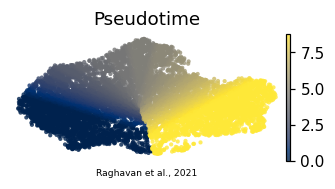

In [8]:
# save manifold + manifold.pdf (pseudotime on the house linear layout, (3.5,1.5) strip)
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')